# Pakistan Electricity Access (1990–2024)
### A complete, lightweight exploratory data analysis and forecasting notebook

**Dataset:** [Pakistan Electricity Access — Kaggle](https://www.kaggle.com/datasets/awahab111/pakistan-electricity-access)  
**Primary source:** World Bank, World Development Indicators (WDI)  
**Coverage:** 1990–2024 | **Indicators:** 4 | **Geography:** Pakistan
**Notebook Author:** Mobeen fatima | @mobeenfatimah

---

## Project objectives
1. Load and validate the annual electricity-access dataset.
2. Explore national, urban and rural access alongside electricity consumption.
3. Identify long-term trends, year-to-year changes and the urban–rural access gap.
4. Create clear, presentation-ready visualizations.
5. Produce an **illustrative 2025–2030 projection** using a simple, transparent trend model.

## Important interpretation notes
- Electricity access means having an electricity connection; it does **not** measure reliability, outage duration or load shedding.
- Consumption is measured in kWh per person and includes grid losses.
- The dataset uses one source (World Bank WDI), not multiple independent sources.
- The forecast is an extrapolation, not an official World Bank forecast. Access percentages are bounded between 0% and 100%.
- Missing World Bank observations are preserved as missing; this notebook does not invent or impute historical values.

## How to run
Place `pakistan_electricity_access_wide.csv` beside this notebook, or allow the first data-loading cell to attempt a public Kaggle download. The notebook uses common scientific Python packages and is designed to run quickly on a CPU.

## 1. Import the libraries
Load only the libraries needed for data handling, statistics and plotting. No heavy machine-learning framework is required.

In [1]:
import os, glob, zipfile, io, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
from IPython.display import display
warnings.filterwarnings("ignore")
plt.rcParams.update({
    "figure.figsize": (10, 5.5), "figure.dpi": 110,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.titleweight": "bold", "axes.titlesize": 14,
    "axes.labelsize": 11, "font.size": 10,
    "grid.alpha": 0.25, "axes.grid": True
})
pd.set_option("display.max_columns", 20)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")
print("Libraries loaded successfully.")

Libraries loaded successfully.


## 2. Set project paths and indicator names
Keep the expected CSV filename and the four World Bank indicator columns in one place.

In [2]:
DATA_FILE = "pakistan_electricity_access_wide.csv"
DATA_DIR = Path(".")
INDICATORS = {
    "access_electricity_pct": "National electricity access (%)",
    "access_urban_pct": "Urban electricity access (%)",
    "access_rural_pct": "Rural electricity access (%)",
    "electric_power_consumption_kwh_pc": "Electricity consumption (kWh per capita)"
}
ACCESS_COLS = ["access_electricity_pct", "access_urban_pct", "access_rural_pct"]
print("Expected file:", DATA_FILE)
print("Expected indicators:", len(INDICATORS))

Expected file: pakistan_electricity_access_wide.csv
Expected indicators: 4


## 3. Locate the dataset locally
Search the notebook folder and common Kaggle input folders before attempting a download.

In [3]:
candidate_paths = [
    Path(DATA_FILE),
    Path("data") / DATA_FILE,
    Path("/kaggle/input/pakistan-electricity-access") / DATA_FILE
]
for root in [Path("/kaggle/input"), Path(".")]:
    if root.exists():
        candidate_paths.extend(Path(p) for p in glob.glob(str(root / "**" / DATA_FILE), recursive=True))
existing = next((p for p in candidate_paths if p.exists()), None)
print("Found:", existing if existing else "No local CSV found yet.")

Found: /kaggle/input/datasets/awahab111/pakistan-electricity-access/pakistan_electricity_access_wide.csv


## 4. Download from Kaggle if needed
For a public dataset, try Kaggle's download endpoint. If network access is unavailable, download the CSV manually from the dataset page and put it beside this notebook.

In [4]:
if existing is None:
    try:
        import requests
        url = "https://www.kaggle.com/api/v1/datasets/download/awahab111/pakistan-electricity-access"
        response = requests.get(url, timeout=45)
        response.raise_for_status()
        with zipfile.ZipFile(io.BytesIO(response.content)) as zf:
            matches = [n for n in zf.namelist() if n.endswith(DATA_FILE)]
            if not matches:
                raise FileNotFoundError(f"{DATA_FILE} was not found inside the Kaggle archive.")
            extracted = zf.read(matches[0])
            Path(DATA_FILE).write_bytes(extracted)
        existing = Path(DATA_FILE)
        print("Dataset downloaded and saved.")
    except Exception as exc:
        print("Automatic download was not successful:", type(exc).__name__, str(exc)[:250])
        print("Please download the wide CSV from Kaggle and place it beside this notebook.")

## 5. Load the wide-format dataset
The wide file is best for year-based plots and modeling: one row per year and one column per indicator.

In [5]:
if existing is None or not existing.exists():
    raise FileNotFoundError(
        f"Could not find {DATA_FILE}. Download the Kaggle dataset and place its wide CSV beside this notebook."
    )
df = pd.read_csv(existing)
print("Loaded dataset:", df.shape)
display(df.head())

Loaded dataset: (35, 6)


,country_code,year,access_electricity_pct,access_urban_pct,access_rural_pct,electric_power_consumption_kwh_pc
0,PAK,1990,NaN,NaN,NaN,257.11
1,PAK,1991,NaN,NaN,NaN,274.21
2,PAK,1992,NaN,NaN,NaN,307.41
3,PAK,1993,NaN,NaN,NaN,307.82
4,PAK,1994,NaN,NaN,NaN,316.36


## 6. Inspect the dataset dimensions
Confirm the expected number of annual rows and columns. The dataset description reports 35 years and four indicators.

In [6]:
print(f"Rows: {df.shape[0]} | Columns: {df.shape[1]}")
print("Column names:", df.columns.tolist())
print("Year range:", df["year"].min(), "to", df["year"].max())

Rows: 35 | Columns: 6
Column names: ['country_code', 'year', 'access_electricity_pct', 'access_urban_pct', 'access_rural_pct', 'electric_power_consumption_kwh_pc']
Year range: 1990 to 2024


## 7. Inspect data types
Check that the year and indicator columns were parsed as numeric values.

In [7]:
display(df.dtypes.to_frame("data_type"))
for col in ["year", *INDICATORS.keys()]:
    if col in df.columns:
        df[col] = pd.to_numeric(df[col], errors="coerce")
print("Numeric conversion complete.")

,data_type
country_code,object
year,int64
access_electricity_pct,float64
access_urban_pct,float64
access_rural_pct,float64
electric_power_consumption_kwh_pc,float64


Numeric conversion complete.


## 8. Validate required columns
Stop early with a helpful message if the CSV structure differs from the published dataset.

In [8]:
required = {"year", *INDICATORS.keys()}
missing_cols = required.difference(df.columns)
if missing_cols:
    raise ValueError(f"Missing required columns: {sorted(missing_cols)}")
print("All required columns are present.")

All required columns are present.


## 9. Sort years and check duplicates
Chronological order is important for changes, rolling averages and forecasting.

In [9]:
df = df.sort_values("year").reset_index(drop=True)
duplicate_years = df.loc[df["year"].duplicated(keep=False), "year"].tolist()
print("Duplicate years:", duplicate_years if duplicate_years else "None")
print("Years are sorted:", df["year"].is_monotonic_increasing)

Duplicate years: None
Years are sorted: True


## 10. Missing-value audit
The World Bank does not publish every indicator for every year. Missing cells are retained and reported.

In [10]:
missing_summary = pd.DataFrame({
    "missing_count": df[list(INDICATORS)].isna().sum(),
    "available_count": df[list(INDICATORS)].notna().sum(),
    "missing_percent": df[list(INDICATORS)].isna().mean().mul(100)
})
display(missing_summary.round(2))

,missing_count,available_count,missing_percent
access_electricity_pct,8,27,22.86
access_urban_pct,8,27,22.86
access_rural_pct,8,27,22.86
electric_power_consumption_kwh_pc,0,35,0.00


## 11. Check value ranges
Access indicators should be between 0 and 100. Consumption should be non-negative.

In [11]:
range_checks = {
    col: {
        "minimum": df[col].min(),
        "maximum": df[col].max(),
        "out_of_range": int(((df[col] < 0) | (df[col] > 100)).sum())
    } for col in ACCESS_COLS
}
range_checks["electric_power_consumption_kwh_pc"] = {
    "minimum": df["electric_power_consumption_kwh_pc"].min(),
    "maximum": df["electric_power_consumption_kwh_pc"].max(),
    "out_of_range": int((df["electric_power_consumption_kwh_pc"] < 0).sum())
}
display(pd.DataFrame(range_checks).T)

,minimum,maximum,out_of_range
access_electricity_pct,70.27,95.70,0.00
access_urban_pct,93.14,100.00,0.00
access_rural_pct,58.96,94.00,0.00
electric_power_consumption_kwh_pc,257.11,570.20,0.00


## 12. Descriptive statistics
Review the distribution of each indicator across its published years.

In [12]:
display(df[list(INDICATORS)].describe().T.round(2))

,count,mean,std,min,25%,50%,75%,max
access_electricity_pct,27.00,85.11,8.66,70.27,77.55,87.80,93.05,95.70
access_urban_pct,27.00,96.77,2.27,93.14,94.75,96.90,98.65,100.00
access_rural_pct,27.00,79.02,11.69,58.96,68.70,82.90,89.60,94.00
electric_power_consumption_kwh_pc,35.00,394.87,78.58,257.11,327.74,389.26,445.56,570.20


## 13. Create a long-format copy
A tidy version makes it easier to compare indicators and build grouped summaries.

In [13]:
long_df = df.melt(
    id_vars="year", value_vars=list(INDICATORS),
    var_name="indicator", value_name="value"
)
long_df["indicator_label"] = long_df["indicator"].map(INDICATORS)
display(long_df.head(8))

,year,indicator,value,indicator_label
0,1990,access_electricity_pct,NaN,National electricity access (%)
1,1991,access_electricity_pct,NaN,National electricity access (%)
2,1992,access_electricity_pct,NaN,National electricity access (%)
3,1993,access_electricity_pct,NaN,National electricity access (%)
4,1994,access_electricity_pct,NaN,National electricity access (%)
5,1995,access_electricity_pct,NaN,National electricity access (%)
6,1996,access_electricity_pct,NaN,National electricity access (%)
7,1997,access_electricity_pct,NaN,National electricity access (%)


## 14. Check observation coverage by indicator
Different indicators can have different year coverage. This table makes that explicit.

In [14]:
coverage = long_df.groupby(["indicator", "indicator_label"]).agg(
    first_year=("year", lambda s: long_df.loc[s.index][long_df.loc[s.index, "value"].notna()]["year"].min()),
    last_year=("year", lambda s: long_df.loc[s.index][long_df.loc[s.index, "value"].notna()]["year"].max()),
    observations=("value", "count")
).reset_index()
display(coverage[["indicator_label", "first_year", "last_year", "observations"]])

,indicator_label,first_year,last_year,observations
0,National electricity access (%),1998,2024,27
1,Rural electricity access (%),1998,2024,27
2,Urban electricity access (%),1998,2024,27
3,Electricity consumption (kWh per capita),1990,2024,35


## 15. Plot national electricity access
A simple time-series line chart shows the long-run direction of national access.

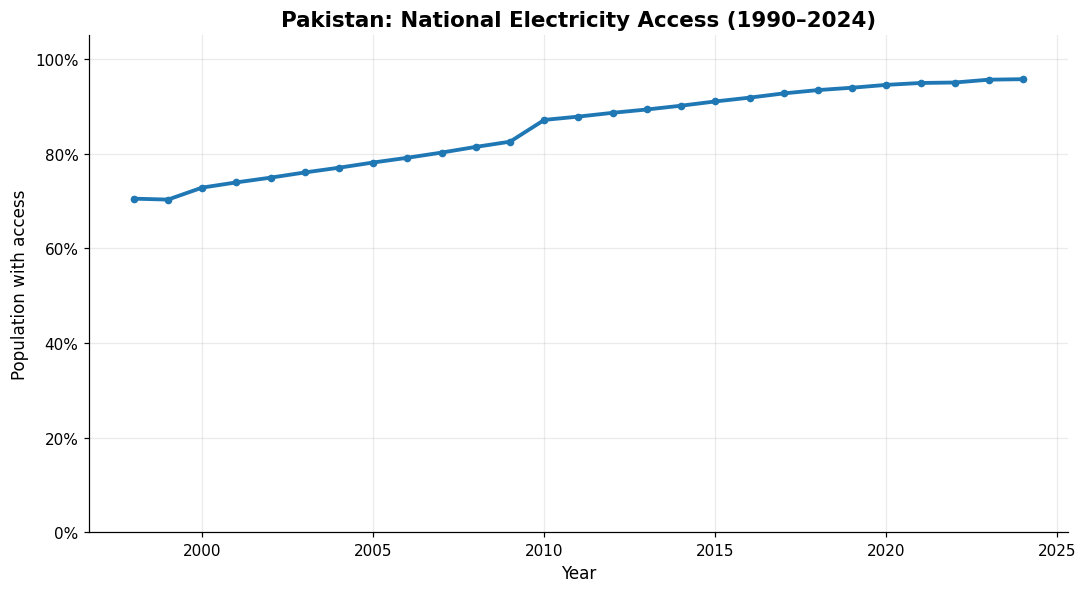

In [15]:
fig, ax = plt.subplots()
ax.plot(df["year"], df["access_electricity_pct"], marker="o", linewidth=2.5, markersize=4)
ax.set(title="Pakistan: National Electricity Access (1990–2024)",
       xlabel="Year", ylabel="Population with access")
ax.yaxis.set_major_formatter(mtick.PercentFormatter(xmax=100))
ax.set_ylim(0, 105)
plt.tight_layout()
plt.show()

## 16. Compare urban and rural access
Plot both population groups on the same scale to see how the access gap changes.

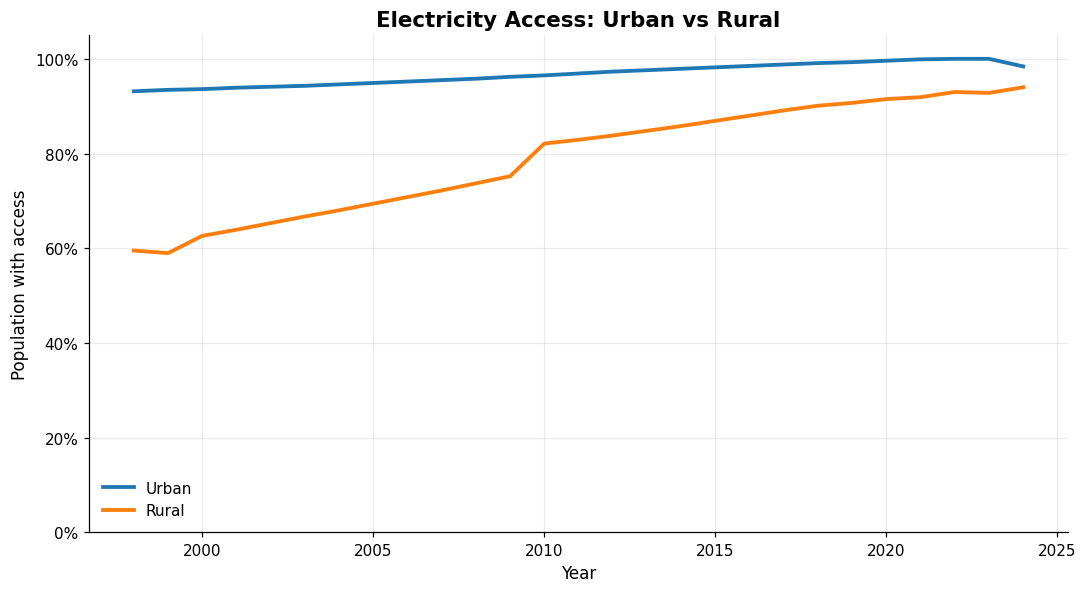

In [16]:
fig, ax = plt.subplots()
ax.plot(df.year, df.access_urban_pct, label="Urban", linewidth=2.5)
ax.plot(df.year, df.access_rural_pct, label="Rural", linewidth=2.5)
ax.set(title="Electricity Access: Urban vs Rural",
       xlabel="Year", ylabel="Population with access")
ax.yaxis.set_major_formatter(mtick.PercentFormatter(xmax=100))
ax.set_ylim(0, 105)
ax.legend(frameon=False)
plt.tight_layout()
plt.show()

## 17. Plot all three access indicators
This overview compares national, urban and rural access in a single figure.

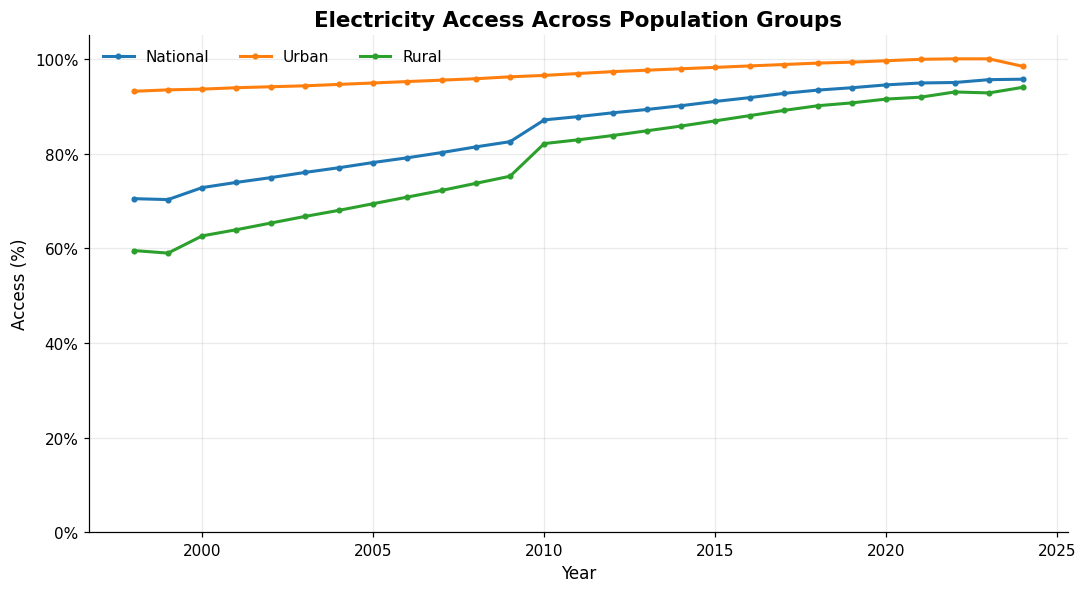

In [17]:
fig, ax = plt.subplots()
for col, label in [
    ("access_electricity_pct", "National"),
    ("access_urban_pct", "Urban"),
    ("access_rural_pct", "Rural")
]:
    ax.plot(df.year, df[col], marker=".", linewidth=2, label=label)
ax.set(title="Electricity Access Across Population Groups",
       xlabel="Year", ylabel="Access (%)")
ax.yaxis.set_major_formatter(mtick.PercentFormatter(xmax=100))
ax.set_ylim(0, 105)
ax.legend(frameon=False, ncol=3)
plt.tight_layout()
plt.show()

## 18. Calculate the urban–rural access gap
The gap is defined as urban access minus rural access, in percentage points.

In [18]:
df["urban_rural_gap_pp"] = df["access_urban_pct"] - df["access_rural_pct"]
display(df[["year", "access_urban_pct", "access_rural_pct", "urban_rural_gap_pp"]].tail(10))

,year,access_urban_pct,access_rural_pct,urban_rural_gap_pp
25,2015,98.20,86.90,11.30
26,2016,98.50,88.00,10.50
27,2017,98.80,89.10,9.70
28,2018,99.10,90.10,9.00
29,2019,99.30,90.70,8.60
30,2020,99.60,91.50,8.10
31,2021,99.90,91.90,8.00
32,2022,100.00,93.00,7.00
33,2023,100.00,92.80,7.20
34,2024,98.40,94.00,4.40


## 19. Visualize the access gap
A falling gap indicates that rural access is catching up with urban access.

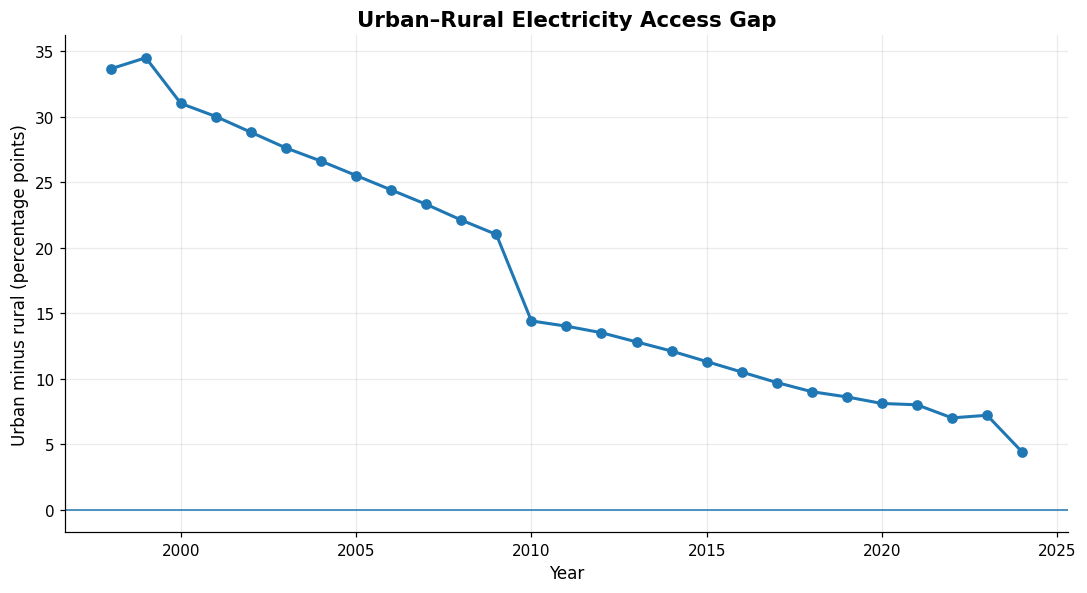

In [19]:
fig, ax = plt.subplots()
ax.plot(df.year, df.urban_rural_gap_pp, marker="o", linewidth=2)
ax.axhline(0, linewidth=1)
ax.set(title="Urban–Rural Electricity Access Gap",
       xlabel="Year", ylabel="Urban minus rural (percentage points)")
plt.tight_layout()
plt.show()

## 20. Quantify rural catch-up since 1998
Compare the earliest available observation from 1998 onward with the latest published year.

In [20]:
rural_period = df.loc[df.year >= 1998, ["year", "access_urban_pct", "access_rural_pct", "urban_rural_gap_pp"]].dropna()
if len(rural_period) >= 2:
    start, end = rural_period.iloc[0], rural_period.iloc[-1]
    print(f"Comparison: {int(start.year)} to {int(end.year)}")
    print(f"Rural access change: {end.access_rural_pct - start.access_rural_pct:.2f} percentage points")
    print(f"Urban access change: {end.access_urban_pct - start.access_urban_pct:.2f} percentage points")
    print(f"Gap change: {end.urban_rural_gap_pp - start.urban_rural_gap_pp:.2f} percentage points")
else:
    print("Not enough overlapping observations to calculate catch-up.")

Comparison: 1998 to 2024
Rural access change: 34.50 percentage points
Urban access change: 5.26 percentage points
Gap change: -29.24 percentage points


## 21. Plot electricity consumption per capita
Consumption is a separate measure from access and is expressed in kWh per person.

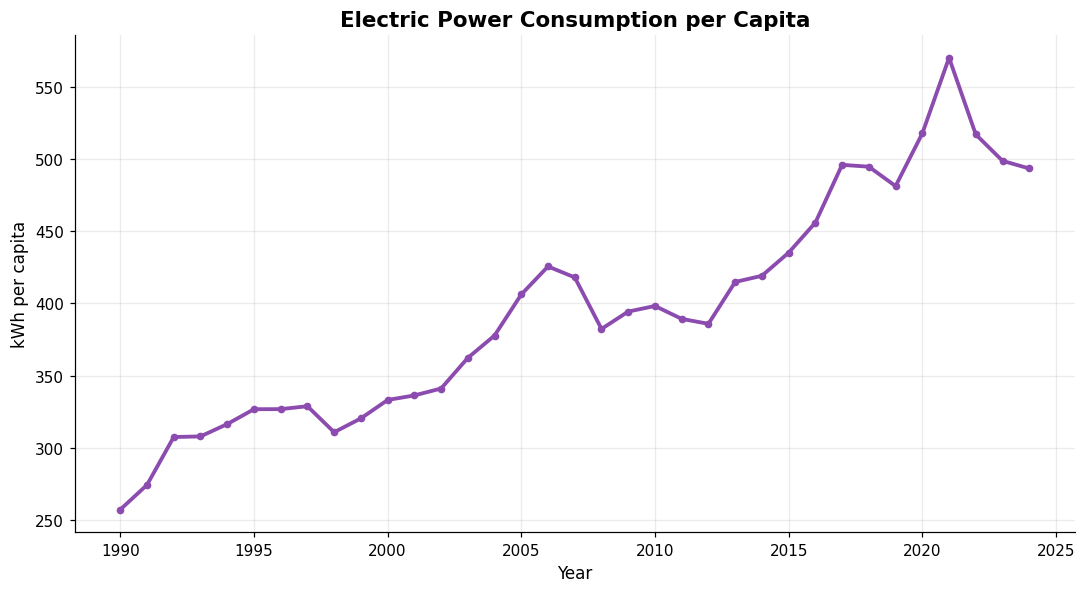

In [21]:
fig, ax = plt.subplots()
ax.plot(df.year, df.electric_power_consumption_kwh_pc, color="#8c4baf",
        marker="o", linewidth=2.5, markersize=4)
ax.set(title="Electric Power Consumption per Capita",
       xlabel="Year", ylabel="kWh per capita")
plt.tight_layout()
plt.show()

## 22. Calculate annual consumption changes
Year-over-year change helps identify periods of growth and decline.

In [22]:
cons = df[["year", "electric_power_consumption_kwh_pc"]].dropna().copy()
cons["change_kwh"] = cons["electric_power_consumption_kwh_pc"].diff()
cons["change_percent"] = cons["electric_power_consumption_kwh_pc"].pct_change() * 100
display(cons.tail(12).round(2))

,year,electric_power_consumption_kwh_pc,change_kwh,change_percent
23,2013,414.85,29.00,7.52
24,2014,419.13,4.28,1.03
25,2015,435.14,16.01,3.82
26,2016,455.97,20.83,4.79
27,2017,496.00,40.03,8.78
28,2018,494.72,-1.28,-0.26
29,2019,481.28,-13.44,-2.72
30,2020,517.77,36.48,7.58
31,2021,570.20,52.44,10.13
32,2022,517.07,-53.13,-9.32


## 23. Visualize annual consumption changes
Bars above zero indicate growth; bars below zero indicate a decline from the previous published observation.

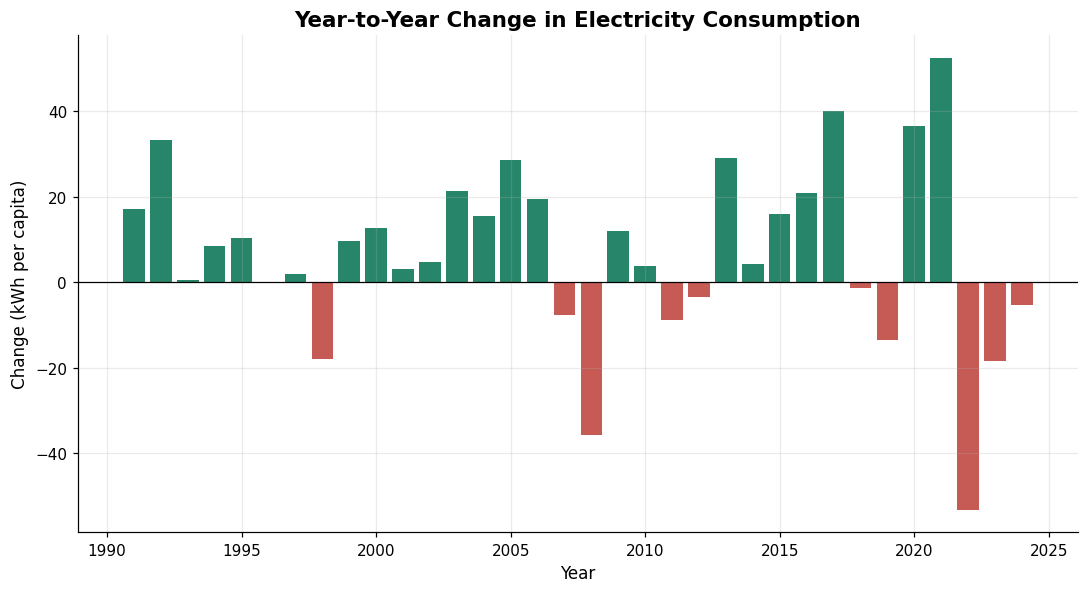

In [23]:
fig, ax = plt.subplots()
colors = np.where(cons["change_kwh"].fillna(0) >= 0, "#27866a", "#c65a54")
ax.bar(cons.year, cons.change_kwh, color=colors, width=0.8)
ax.axhline(0, color="black", linewidth=0.8)
ax.set(title="Year-to-Year Change in Electricity Consumption",
       xlabel="Year", ylabel="Change (kWh per capita)")
plt.tight_layout()
plt.show()

## 24. List the strongest consumption increases and decreases
Rank observed year-to-year changes without treating them as causal explanations.

In [24]:
valid_changes = cons.dropna(subset=["change_kwh"])
print("Largest increases:")
display(valid_changes.nlargest(5, "change_kwh")[["year", "change_kwh", "change_percent"]].round(2))
print("Largest decreases:")
display(valid_changes.nsmallest(5, "change_kwh")[["year", "change_kwh", "change_percent"]].round(2))

Largest increases:


,year,change_kwh,change_percent
31,2021,52.44,10.13
27,2017,40.03,8.78
30,2020,36.48,7.58
2,1992,33.19,12.11
23,2013,29.00,7.52


Largest decreases:


,year,change_kwh,change_percent
32,2022,-53.13,-9.32
18,2008,-35.69,-8.54
33,2023,-18.30,-3.54
8,1998,-18.02,-5.48
29,2019,-13.44,-2.72


## 25. Compare access and consumption in a dual-axis chart
The two measures use different units, so separate y-axes are used. Interpret the scales independently.

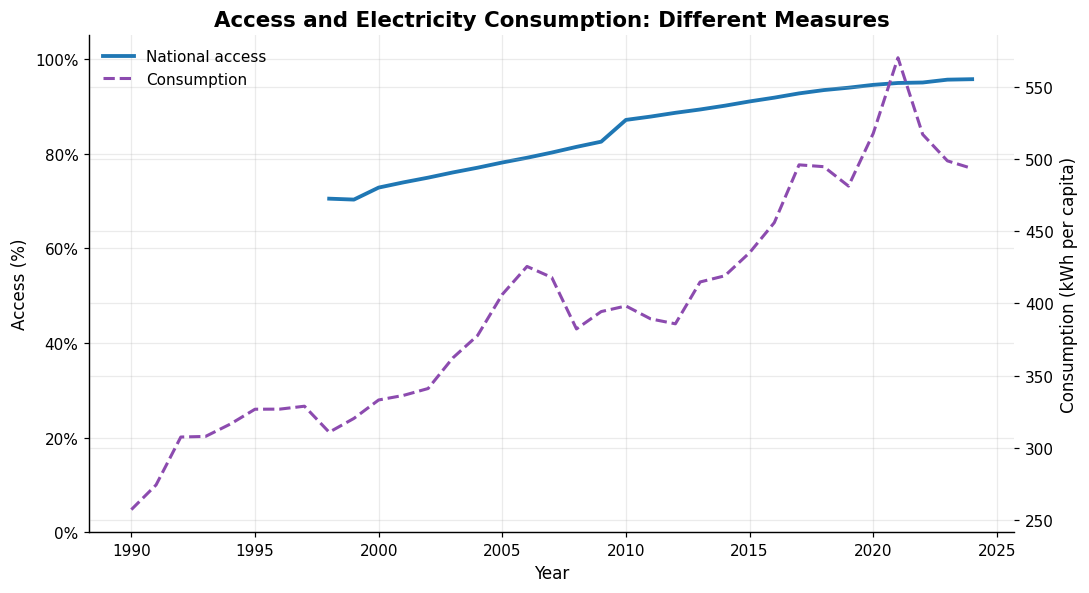

In [25]:
fig, ax1 = plt.subplots()
ax1.plot(df.year, df.access_electricity_pct, linewidth=2.5, label="National access")
ax1.set_xlabel("Year")
ax1.set_ylabel("Access (%)")
ax1.yaxis.set_major_formatter(mtick.PercentFormatter(xmax=100))
ax1.set_ylim(0, 105)
ax2 = ax1.twinx()
ax2.plot(df.year, df.electric_power_consumption_kwh_pc,
         color="#8c4baf", linewidth=2, linestyle="--", label="Consumption")
ax2.set_ylabel("Consumption (kWh per capita)")
ax1.set_title("Access and Electricity Consumption: Different Measures")
lines = ax1.get_lines() + ax2.get_lines()
ax1.legend(lines, [line.get_label() for line in lines], frameon=False, loc="best")
plt.tight_layout()
plt.show()

## 26. Examine the relationship between access and consumption
Use only years where both indicators are available. Correlation describes association, not causation.

In [26]:
paired = df[["access_electricity_pct", "electric_power_consumption_kwh_pc"]].dropna()
if len(paired) >= 3:
    corr = paired.corr().iloc[0, 1]
    print(f"Pearson correlation (n={len(paired)} paired years): {corr:.3f}")
else:
    print("Not enough paired observations for correlation.")

Pearson correlation (n=27 paired years): 0.893


## 27. Scatter plot: access vs consumption
Each point represents one year. This helps assess whether higher access coincides with higher per-capita consumption.

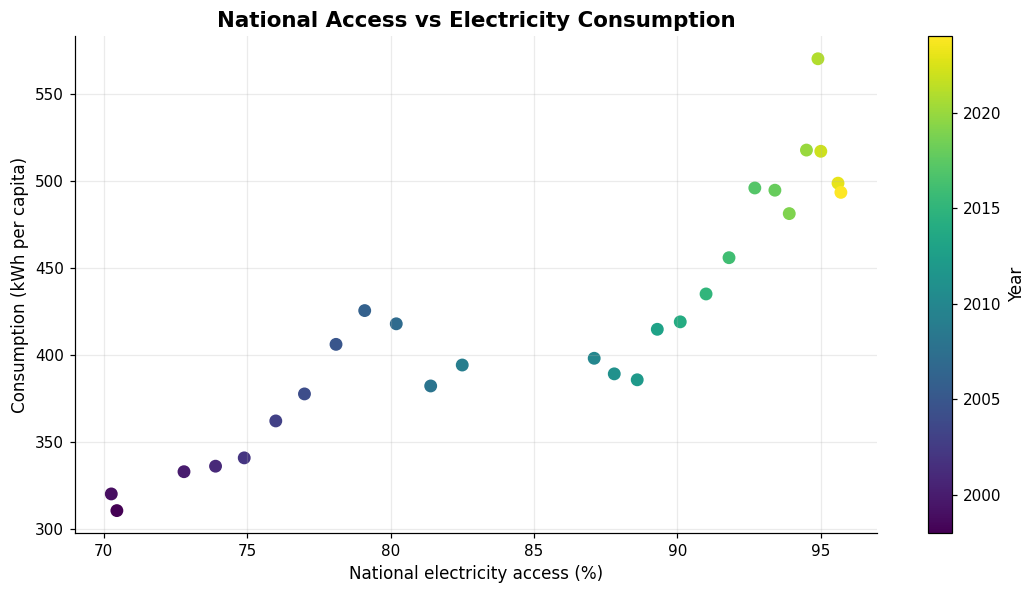

In [27]:
fig, ax = plt.subplots()
scatter = ax.scatter(paired.access_electricity_pct,
                     paired.electric_power_consumption_kwh_pc,
                     c=df.loc[paired.index, "year"], cmap="viridis", s=55)
ax.set(title="National Access vs Electricity Consumption",
       xlabel="National electricity access (%)",
       ylabel="Consumption (kWh per capita)")
cbar = plt.colorbar(scatter, ax=ax)
cbar.set_label("Year")
plt.tight_layout()
plt.show()

## 28. Add a three-year rolling average
A rolling average smooths short-term fluctuations. It is descriptive, not a replacement for the original series.

In [28]:
df["consumption_rolling_3y"] = df["electric_power_consumption_kwh_pc"].rolling(
    window=3, min_periods=2
).mean()
display(df[["year", "electric_power_consumption_kwh_pc", "consumption_rolling_3y"]].tail(10))

,year,electric_power_consumption_kwh_pc,consumption_rolling_3y
25,2015,435.14,423.04
26,2016,455.97,436.75
27,2017,496.00,462.37
28,2018,494.72,482.23
29,2019,481.28,490.67
30,2020,517.77,497.92
31,2021,570.20,523.08
32,2022,517.07,535.01
33,2023,498.77,528.68
34,2024,493.47,503.10


## 29. Plot original consumption and its rolling average
The original line preserves observed values; the smoother line highlights the broad pattern.

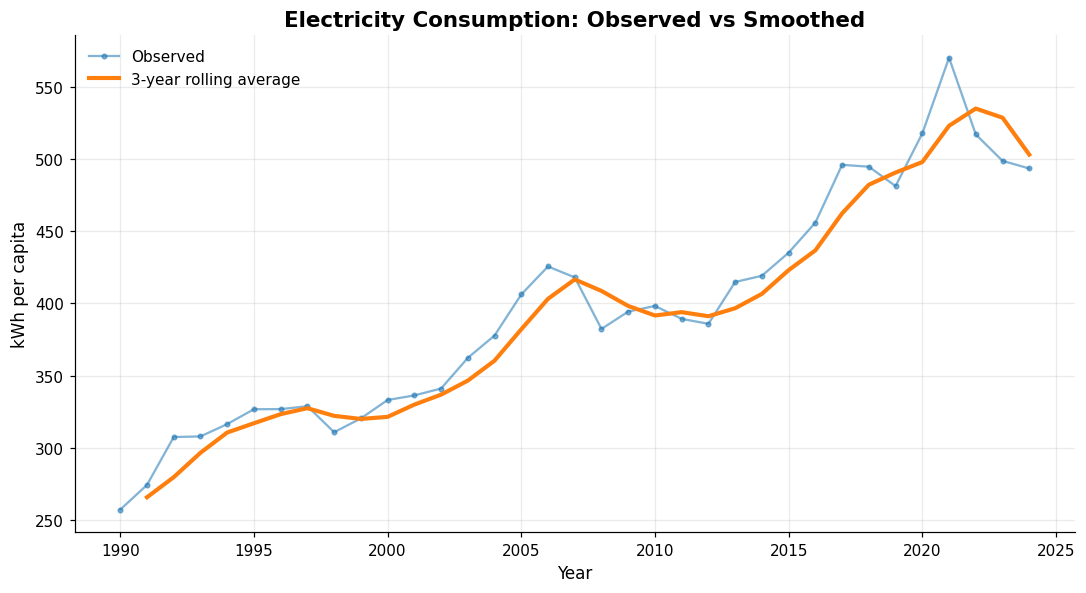

In [29]:
fig, ax = plt.subplots()
ax.plot(df.year, df.electric_power_consumption_kwh_pc,
        marker=".", alpha=0.55, label="Observed")
ax.plot(df.year, df.consumption_rolling_3y,
        linewidth=2.7, label="3-year rolling average")
ax.set(title="Electricity Consumption: Observed vs Smoothed",
       xlabel="Year", ylabel="kWh per capita")
ax.legend(frameon=False)
plt.tight_layout()
plt.show()

## 30. Compare early and recent periods
Use available values to compare the 1990s with the most recent decade in the dataset.

In [30]:
period_df = df.copy()
period_df["period"] = pd.cut(
    period_df.year, bins=[1989, 1999, 2009, 2019, 2024],
    labels=["1990s", "2000s", "2010s", "2020–2024"]
)
period_summary = period_df.groupby("period", observed=False)[list(INDICATORS)].mean()
display(period_summary.round(2))

,access_electricity_pct,access_urban_pct,access_rural_pct,electric_power_consumption_kwh_pc
period,,,,
1990s,70.36,93.29,59.23,307.61
2000s,77.59,94.81,68.78,377.67
2010s,90.57,98.01,86.42,437.04
2020–2024,95.14,99.58,92.64,519.46


## 31. Visualize average access by period
This compact comparison shows how the average access levels differ across broad time windows.

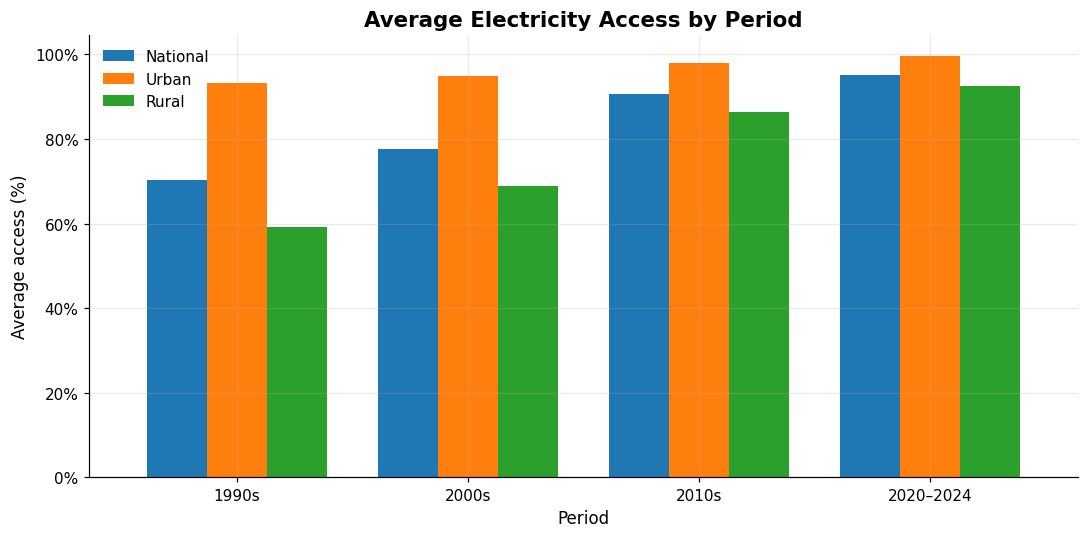

In [31]:
period_access = period_summary[ACCESS_COLS]
ax = period_access.plot(kind="bar", figsize=(10, 5), width=0.78)
ax.set(title="Average Electricity Access by Period",
       xlabel="Period", ylabel="Average access (%)")
ax.yaxis.set_major_formatter(mtick.PercentFormatter(xmax=100))
ax.legend(["National", "Urban", "Rural"], frameon=False)
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

## 32. Create a latest-year snapshot
Report the latest available value separately for each indicator because coverage can differ.

In [32]:
latest_rows = []
for col, label in INDICATORS.items():
    available = df[["year", col]].dropna()
    if not available.empty:
        row = available.iloc[-1]
        latest_rows.append({"Indicator": label, "Latest year": int(row.year), "Latest value": row[col]})
latest_snapshot = pd.DataFrame(latest_rows)
display(latest_snapshot.round(2))

,Indicator,Latest year,Latest value
0,National electricity access (%),2024,95.70
1,Urban electricity access (%),2024,98.40
2,Rural electricity access (%),2024,94.00
3,Electricity consumption (kWh per capita),2024,493.47


## 33. Build a compact key-metrics table
Calculate the latest urban–rural gap and summarize the latest access and consumption observations.

In [33]:
def latest_value(column):
    s = df[["year", column]].dropna()
    return int(s.iloc[-1].year), float(s.iloc[-1][column])
metrics = {}
for col in INDICATORS:
    yr, val = latest_value(col)
    metrics[INDICATORS[col]] = f"{val:.1f} ({yr})"
gap_data = df[["year", "urban_rural_gap_pp"]].dropna()
if not gap_data.empty:
    metrics["Urban–rural gap (percentage points)"] = f"{gap_data.iloc[-1].urban_rural_gap_pp:.1f} ({int(gap_data.iloc[-1].year)})"
display(pd.DataFrame.from_dict(metrics, orient="index", columns=["Latest observation"]))

,Latest observation
National electricity access (%),95.7 (2024)
Urban electricity access (%),98.4 (2024)
Rural electricity access (%),94.0 (2024)
Electricity consumption (kWh per capita),493.5 (2024)
Urban–rural gap (percentage points),4.4 (2024)


## 34. Prepare the national access series for forecasting
Use published national-access observations only. Missing historical values are excluded, not filled.

In [34]:
forecast_data = df[["year", "access_electricity_pct"]].dropna().copy()
forecast_data = forecast_data.sort_values("year")
print("Observations used:", len(forecast_data))
print("Training period:", int(forecast_data.year.min()), "to", int(forecast_data.year.max()))
display(forecast_data.tail())

Observations used: 27
Training period: 1998 to 2024


,year,access_electricity_pct
30,2020,94.50
31,2021,94.90
32,2022,95.00
33,2023,95.60
34,2024,95.70


## 35. Fit a simple linear trend model
Fit a first-degree polynomial to observed national access. This lightweight approach runs quickly and is easy to explain.

In [35]:
if len(forecast_data) < 3:
    raise ValueError("At least three published access observations are needed for this simple trend model.")
slope, intercept = np.polyfit(forecast_data["year"], forecast_data["access_electricity_pct"], 1)
fitted = slope * forecast_data["year"] + intercept
ss_res = np.sum((forecast_data["access_electricity_pct"] - fitted) ** 2)
ss_tot = np.sum((forecast_data["access_electricity_pct"] - forecast_data["access_electricity_pct"].mean()) ** 2)
r_squared = 1 - ss_res / ss_tot if ss_tot else np.nan
print(f"Annual linear trend: {slope:.3f} percentage points per year")
print(f"Training R-squared: {r_squared:.3f}")

Annual linear trend: 1.072 percentage points per year
Training R-squared: 0.967


## 36. Inspect model fit on historical observations
Compare observed values with the fitted linear trend. A high R-squared does not guarantee accurate future predictions.

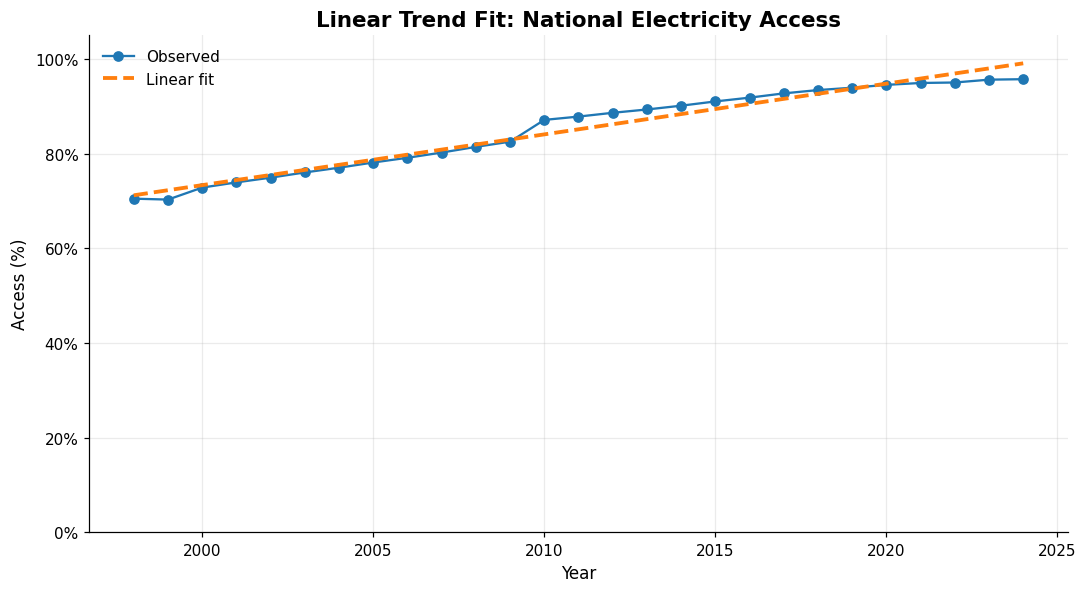

In [36]:
fig, ax = plt.subplots()
ax.plot(forecast_data.year, forecast_data.access_electricity_pct,
        marker="o", label="Observed")
ax.plot(forecast_data.year, fitted, linestyle="--", linewidth=2.5, label="Linear fit")
ax.set(title="Linear Trend Fit: National Electricity Access",
       xlabel="Year", ylabel="Access (%)")
ax.yaxis.set_major_formatter(mtick.PercentFormatter(xmax=100))
ax.set_ylim(0, 105)
ax.legend(frameon=False)
plt.tight_layout()
plt.show()

## 37. Generate the 2025–2030 projection
Project six years beyond the latest dataset year and clip predictions to the valid 0–100% range.

In [37]:
future_years = np.arange(2025, 2031)
raw_predictions = slope * future_years + intercept
future_predictions = np.clip(raw_predictions, 0, 100)
projection = pd.DataFrame({
    "year": future_years,
    "linear_projection_pct": raw_predictions,
    "bounded_projection_pct": future_predictions
})
display(projection.round(2))

,year,linear_projection_pct,bounded_projection_pct
0,2025,100.12,100.00
1,2026,101.19,100.00
2,2027,102.27,100.00
3,2028,103.34,100.00
4,2029,104.41,100.00
5,2030,105.48,100.00


## 38. Plot historical access and the projection
The dashed segment is a model-based scenario, not observed data or an official forecast.

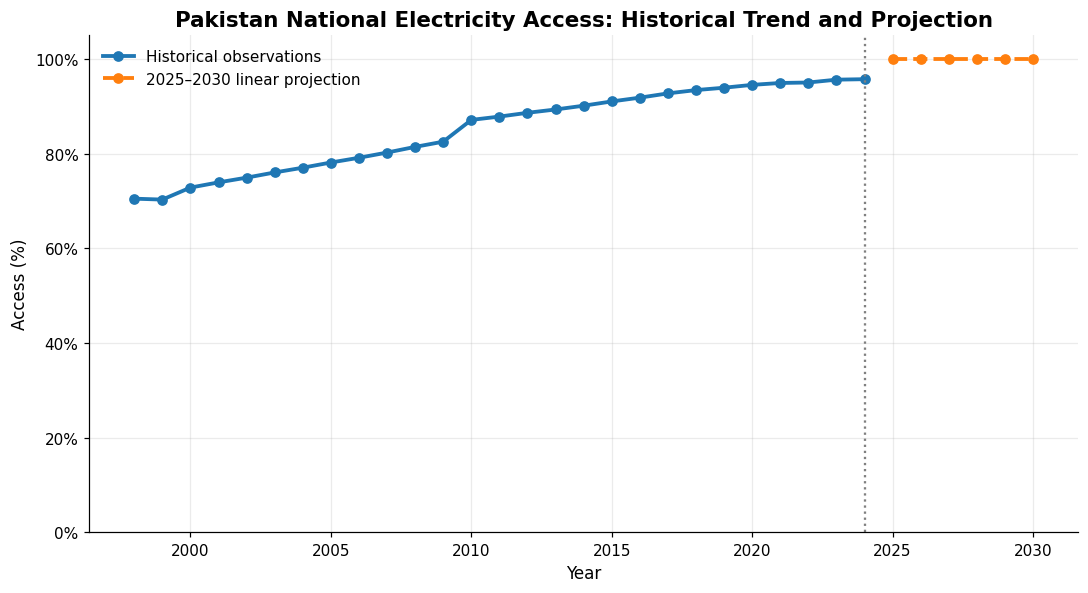

In [38]:
fig, ax = plt.subplots()
ax.plot(forecast_data.year, forecast_data.access_electricity_pct,
        marker="o", linewidth=2.5, label="Historical observations")
ax.plot(future_years, future_predictions, marker="o", linestyle="--",
        linewidth=2.5, label="2025–2030 linear projection")
ax.axvline(forecast_data.year.max(), color="gray", linestyle=":", linewidth=1.5)
ax.set(title="Pakistan National Electricity Access: Historical Trend and Projection",
       xlabel="Year", ylabel="Access (%)")
ax.yaxis.set_major_formatter(mtick.PercentFormatter(xmax=100))
ax.set_ylim(0, 105)
ax.legend(frameon=False)
plt.tight_layout()
plt.show()

## 39. Estimate when the linear trend reaches 100%
If the fitted slope is positive, calculate the trend's theoretical 100% crossing year. Treat this as a mathematical extrapolation only.

In [39]:
if slope > 0:
    year_to_100 = (100 - intercept) / slope
    print(f"Linear trend reaches 100% at approximately year {year_to_100:.1f}.")
else:
    print("The fitted trend is not positive; a 100% crossing year is not meaningful.")

Linear trend reaches 100% at approximately year 2024.9.


## 40. Export analysis-ready tables
Save the cleaned wide data, tidy long data, consumption changes and forecast to CSV files.

In [40]:
df.to_csv("pakistan_electricity_cleaned.csv", index=False)
long_df.to_csv("pakistan_electricity_long_analysis.csv", index=False)
cons.to_csv("pakistan_electricity_consumption_changes.csv", index=False)
projection.to_csv("pakistan_electricity_access_projection_2025_2030.csv", index=False)
print("Exported 4 CSV files to:", Path(".").resolve())

Exported 4 CSV files to: /kaggle/working


## 41. Export the key visualizations
Save high-resolution PNG figures that can be reused in a report or presentation.

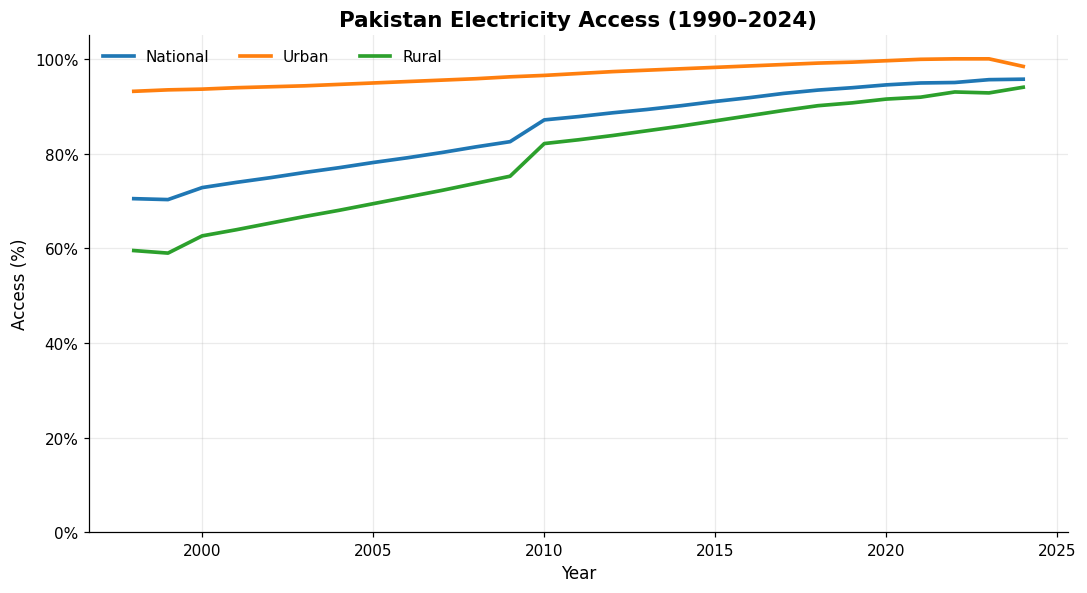

Saved electricity_access_trends.png


In [41]:
# Recreate and save a clean access comparison chart
fig, ax = plt.subplots(figsize=(10, 5.5))
for col, label in [("access_electricity_pct", "National"),
                   ("access_urban_pct", "Urban"),
                   ("access_rural_pct", "Rural")]:
    ax.plot(df.year, df[col], linewidth=2.4, label=label)
ax.set(title="Pakistan Electricity Access (1990–2024)",
       xlabel="Year", ylabel="Access (%)")
ax.yaxis.set_major_formatter(mtick.PercentFormatter(xmax=100))
ax.set_ylim(0, 105)
ax.legend(frameon=False, ncol=3)
fig.tight_layout()
fig.savefig("electricity_access_trends.png", dpi=220, bbox_inches="tight")
plt.show()
print("Saved electricity_access_trends.png")

## 42. Final automated checks
Confirm the analysis ran on the expected period and summarize the main data-quality checks.

In [42]:
print("FINAL NOTEBOOK CHECK")
print("-" * 45)
print("Dataset rows:", len(df))
print("Year coverage:", int(df.year.min()), "to", int(df.year.max()))
print("Required columns present:", required.issubset(df.columns))
print("Duplicate years:", int(df.year.duplicated().sum()))
print("Missing values by indicator:")
display(df[list(INDICATORS)].isna().sum().to_frame("missing"))
print("Projection years:", projection.year.tolist())
print("Outputs: 4 CSV files + 1 PNG chart")
print("\nAnalysis complete.")

FINAL NOTEBOOK CHECK
---------------------------------------------
Dataset rows: 35
Year coverage: 1990 to 2024
Required columns present: True
Duplicate years: 0
Missing values by indicator:


,missing
access_electricity_pct,8
access_urban_pct,8
access_rural_pct,8
electric_power_consumption_kwh_pc,0


Projection years: [2025, 2026, 2027, 2028, 2029, 2030]
Outputs: 4 CSV files + 1 PNG chart

Analysis complete.
